In [5]:
for name in ["df", "df_clean", "sales", "before", "label_table", "n_invoices", "recency", "monetary", "features", "features_log", "X"]:
    print(name, name in globals())

df True
df_clean True
sales True
before True
label_table True
n_invoices True
recency False
monetary False
features False
features_log False
X False


چرا؟ این نوت‌بوک تازه است و هیچ متغیری ندارد. سه فایلی را که در نوت‌بوک Data Preparation ذخیره کردیم می‌خوانیم: ویژگی‌های RFM، جدول label و تراکنش‌های تمیز. parse_dates لازم است چون CSV تاریخ را متن می‌خواند. تاریخ cutoff را هم دوباره تعریف می‌کنیم چون مقدار متغیرها در فایل ذخیره نمی‌شود.

تحلیل: شکل‌ها باید (3368, 4)، (3368, 4) و (531205, 9) باشند. یعنی ۳٬۳۶۸ مشتری با سابقه‌ی خرید قبل از cutoff و ۵۳۱٬۲۰۵ ردیف تراکنش تمیز داریم.

In [6]:
import pandas as pd
import numpy as np


df = pd.read_excel("/home/helia/Documents/BaseDir/online+retail/Online Retail.xlsx")
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["is_cancel"] = df["InvoiceNo"].str.startswith("C")

df_clean = df.copy()
removed = []


mask = df_clean["InvoiceNo"].str.startswith("A")
removed.append(df_clean[mask].assign(reason="bad_debt"))
df_clean = df_clean[~mask]


non_product = ["POST", "DOT", "M", "m", "C2", "D", "S","BANK CHARGES", "AMAZONFEE", "CRUK", "B", "PADS"]
mask = df_clean["StockCode"].isin(non_product) | df_clean["StockCode"].str.startswith("gift_")
service_lines = df_clean[mask].copy()
df_clean = df_clean[~mask]


mask = df_clean["UnitPrice"] <= 0
removed.append(df_clean[mask].assign(reason="zero_price"))
df_clean = df_clean[~mask]


mask = df_clean.duplicated()
removed.append(df_clean[mask].assign(reason="duplicate"))
df_clean = df_clean[~mask]


excluded = pd.concat(removed)
print(len(df), len(df_clean), len(service_lines), len(excluded))
print(len(df) == len(df_clean) + len(service_lines) + len(excluded))

541909 531205 2947 7757
True


In [7]:
sales = df_clean[(df_clean["is_cancel"] == False) & (df_clean["CustomerID"].notna())].copy()
sales["CustomerID"] = sales["CustomerID"].astype(int)
print(sales.shape, sales["CustomerID"].nunique())


cutoff = pd.Timestamp("2011-09-11")
before = sales[sales["InvoiceDate"] < cutoff]
after = sales[sales["InvoiceDate"] >= cutoff]
customers_before = before["CustomerID"].unique()
customers_after = after["CustomerID"].unique()


returned = set(customers_after)
churn_ids = [c for c in customers_before if c not in returned]
print(len(customers_before), len(churn_ids))

# جدول label
label_table = pd.DataFrame({"CustomerID": customers_before})
label_table["churn"] = label_table["CustomerID"].isin(churn_ids).astype(int)
n_invoices = before.groupby("CustomerID")["InvoiceNo"].nunique()
label_table["n_invoices"] = label_table["CustomerID"].map(n_invoices)
label_table["for_classification"] = (label_table["n_invoices"] >= 2).astype(int)
print(label_table.shape, label_table["churn"].sum(), label_table["for_classification"].sum())

(391150, 9) 4334
3368 1449
(3368, 4) 1449 1998


In [8]:
before = before.copy()
before["TotalPrice"] = before["Quantity"] * before["UnitPrice"]

last_purchase = before.groupby("CustomerID")["InvoiceDate"].max()
recency = (cutoff - last_purchase).dt.days
monetary = before.groupby("CustomerID")["TotalPrice"].sum()

features = label_table[["CustomerID"]].copy()
features["recency"] = features["CustomerID"].map(recency)
features["frequency"] = features["CustomerID"].map(n_invoices)
features["monetary"] = features["CustomerID"].map(monetary)
print(features.shape, features.isna().sum().sum())


features[["CustomerID", "recency", "frequency", "monetary"]].to_csv("features_rfm.csv", index=False)
label_table.to_csv("label_table.csv", index=False)
df_clean.to_csv("df_clean.csv", index=False)
print("done")

(3368, 4) 0
done


In [9]:
import pandas as pd

features = pd.read_csv("features_rfm.csv")
label_table = pd.read_csv("label_table.csv")
df_clean = pd.read_csv("df_clean.csv", parse_dates=["InvoiceDate"])
cutoff = pd.Timestamp("2011-09-11")

print(features.shape, label_table.shape, df_clean.shape)

(3368, 4) (3368, 4) (531205, 9)


In [10]:
import numpy as np

features_log = features[["recency", "frequency", "monetary"]].copy()
features_log["frequency"] = np.log1p(features_log["frequency"])
features_log["monetary"] = np.log1p(features_log["monetary"])

print(features[["recency", "frequency", "monetary"]].skew().round(2))
print(features_log.skew().round(2))

recency       0.76
frequency     9.17
monetary     16.28
dtype: float64
recency      0.76
frequency    1.38
monetary     0.41
dtype: float64


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(features_log)

X_df = pd.DataFrame(X, columns=["recency", "frequency", "monetary"])
print(X_df.describe().round(2))

       recency  frequency  monetary
count  3368.00    3368.00   3368.00
mean     -0.00       0.00      0.00
std       1.00       1.00      1.00
min      -1.18      -0.87     -4.14
25%      -0.86      -0.87     -0.69
50%      -0.27      -0.22     -0.07
75%       0.71       0.59      0.67
max       2.35       5.82      4.66


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    print(k, round(km.inertia_, 1), round(silhouette_score(X, labels), 3))

2 5228.0 0.411
3 3520.5 0.373
4 2724.5 0.345
5 2346.9 0.325
6 2029.0 0.317
7 1824.5 0.302
8 1672.8 0.28


In [13]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
features["cluster"] = km.fit_predict(X)

print(features["cluster"].value_counts().sort_index())

cluster
0    1118
1     886
2     479
3     885
Name: count, dtype: int64


In [14]:
profile = features.groupby("cluster")[["recency", "frequency", "monetary"]].mean().round(1)
profile["size"] = features["cluster"].value_counts().sort_index()
print(profile)

         recency  frequency  monetary  size
cluster                                    
0           56.7        3.3    1303.8  1118
1          208.3        1.2     351.4   886
2           24.4       12.2    6939.5   479
3           69.0        1.4     301.1   885


In [15]:
features = features.merge(label_table[["CustomerID", "churn"]], on="CustomerID")

print(features.shape)
print(features.head())

(3368, 6)
   CustomerID  recency  frequency  monetary  cluster  churn
0       17850      282         34   5391.21        2      1
1       13047       37          8   2682.01        2      0
2       12583       16          9   3908.21        2      0
3       13748        5          5    948.25        0      1
4       15100      243          3    876.00        1      1


In [16]:
churn_by_cluster = features.groupby("cluster")["churn"].agg(["mean", "sum", "count"])
print(churn_by_cluster.round(3))
print(features["churn"].mean().round(3))

          mean  sum  count
cluster                   
0        0.318  355   1118
1        0.661  586    886
2        0.067   32    479
3        0.538  476    885
0.43


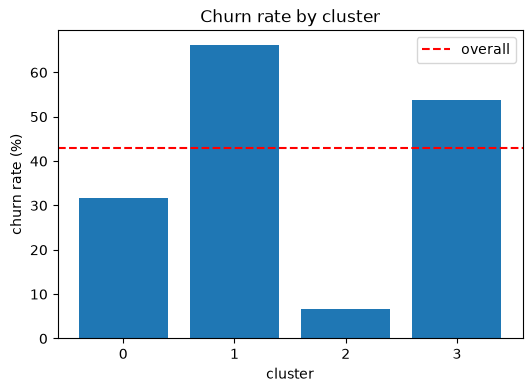

In [17]:
import matplotlib.pyplot as plt

rate = features.groupby("cluster")["churn"].mean()

plt.figure(figsize=(6, 4))
plt.bar(rate.index.astype(str), rate.values * 100)
plt.axhline(features["churn"].mean() * 100, color="red", linestyle="--", label="overall")
plt.xlabel("cluster")
plt.ylabel("churn rate (%)")
plt.title("Churn rate by cluster")
plt.legend()
plt.show()

In [18]:
basket_lines = df_clean[(df_clean["is_cancel"] == False) & (df_clean["InvoiceDate"] < cutoff)].copy()

basket_lines["InvoiceNo"] = basket_lines["InvoiceNo"].astype(str)
basket_lines["StockCode"] = basket_lines["StockCode"].astype(str)

basket_lines = basket_lines[["InvoiceNo", "StockCode"]].drop_duplicates()

print(basket_lines.shape)
print(basket_lines["InvoiceNo"].nunique(), basket_lines["StockCode"].nunique())

(319644, 2)
12897 3662


In [19]:
item_counts = basket_lines["StockCode"].value_counts()
frequent_items = item_counts[item_counts >= 100].index

basket_lines = basket_lines[basket_lines["StockCode"].isin(frequent_items)]

print(len(frequent_items))
print(basket_lines.shape)

1000
(238962, 2)


In [20]:
basket_size = basket_lines.groupby("InvoiceNo").size()
good_invoices = basket_size[basket_size >= 2].index

basket_lines = basket_lines[basket_lines["InvoiceNo"].isin(good_invoices)]

print(basket_lines.shape)
print(basket_lines["InvoiceNo"].nunique(), basket_lines["StockCode"].nunique())

(237966, 2)
11485 1000


In [21]:
basket_matrix = pd.crosstab(basket_lines["InvoiceNo"], basket_lines["StockCode"]).astype(bool)

print(basket_matrix.shape)
print(basket_matrix.sum().sum())
print(basket_matrix.iloc[:3, :5])

(11485, 1000)
237966
StockCode  10133  10135  15036  15039  15056BL
InvoiceNo                                     
536365     False  False  False  False    False
536366     False  False  False  False    False
536367     False  False  False  False    False


In [22]:
import mlxtend
print(mlxtend.__version__)

0.25.0


In [23]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(basket_matrix, min_support=0.02, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

print(frequent_itemsets.shape)
print(frequent_itemsets["length"].value_counts().sort_index())
print(frequent_itemsets.sort_values("support", ascending=False).head())

(533, 3)
length
1    359
2    154
3     20
Name: count, dtype: int64
      support             itemsets  length
356  0.137658  frozenset({85123A})       1
353  0.124771  frozenset({85099B})       1
172  0.123465   frozenset({22423})       1
302  0.118067   frozenset({47566})       1
14   0.099086   frozenset({20725})       1


In [24]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

print(rules.shape)
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values("lift", ascending=False).head())

(132, 14)
            antecedents          consequents   support  confidence       lift
72  frozenset({84596B})  frozenset({84596F})  0.020810    0.690751  26.621746
73  frozenset({84596F})  frozenset({84596B})  0.020810    0.802013  26.621746
29   frozenset({21086})   frozenset({21094})  0.024902    0.826590  22.549600
28   frozenset({21094})   frozenset({21086})  0.024902    0.679335  22.549600
70   frozenset({23300})   frozenset({23301})  0.021855    0.727536  20.941738


In [25]:
desc_map = df_clean.dropna(subset=["Description"]).assign(StockCode=df_clean["StockCode"].astype(str)).groupby("StockCode")["Description"].agg(lambda x: x.mode().iat[0])

def names(itemset):
    return " + ".join(desc_map.get(code, code) for code in itemset)

rules["antecedent_name"] = rules["antecedents"].apply(names)
rules["consequent_name"] = rules["consequents"].apply(names)

show = rules[["antecedent_name", "consequent_name", "support", "confidence", "lift"]]
print(show.sort_values("lift", ascending=False).head(10).round(3).to_string())

                                                        antecedent_name                                                     consequent_name  support  confidence    lift
72                                   SMALL DOLLY MIX DESIGN ORANGE BOWL                                        SMALL MARSHMALLOWS PINK BOWL    0.021       0.691  26.622
73                                         SMALL MARSHMALLOWS PINK BOWL                                  SMALL DOLLY MIX DESIGN ORANGE BOWL    0.021       0.802  26.622
29                                          SET/6 RED SPOTTY PAPER CUPS                                       SET/6 RED SPOTTY PAPER PLATES    0.025       0.827  22.550
28                                        SET/6 RED SPOTTY PAPER PLATES                                         SET/6 RED SPOTTY PAPER CUPS    0.025       0.679  22.550
70                                   GARDENERS KNEELING PAD CUP OF TEA                                    GARDENERS KNEELING PAD KEEP CALM     0.022       

In [26]:
rule_itemsets = set()
for _, row in rules.iterrows():
    rule_itemsets.add(frozenset(row["antecedents"] | row["consequents"]))
print(len(rule_itemsets))

invoice_rule_count = pd.Series(0, index=basket_matrix.index)
for items in rule_itemsets:
    has_all = basket_matrix[list(items)].all(axis=1)
    invoice_rule_count = invoice_rule_count + has_all.astype(int)

print((invoice_rule_count > 0).sum(), (invoice_rule_count > 0).mean().round(3))
print(invoice_rule_count.describe().round(2))

84
4637 0.404
count    11485.00
mean         2.31
std          5.27
min          0.00
25%          0.00
50%          0.00
75%          2.00
max         49.00
dtype: float64


In [27]:
inv_cust = df_clean[(df_clean["is_cancel"] == False) & (df_clean["CustomerID"].notna()) & (df_clean["InvoiceDate"] < cutoff)][["InvoiceNo", "CustomerID"]].drop_duplicates()
inv_cust["InvoiceNo"] = inv_cust["InvoiceNo"].astype(str)
inv_cust["CustomerID"] = inv_cust["CustomerID"].astype(int)
print(inv_cust.shape, inv_cust["CustomerID"].nunique())


inv_cust["rule_count"] = inv_cust["InvoiceNo"].map(invoice_rule_count).fillna(0)
inv_cust["has_rule"] = (inv_cust["rule_count"] > 0).astype(int)


n_rule_invoices = inv_cust.groupby("CustomerID")["has_rule"].sum()
print(n_rule_invoices.describe().round(2))

(11827, 2) 3368
count    3368.00
mean        1.19
std         2.56
min         0.00
25%         0.00
50%         0.00
75%         1.00
max        62.00
Name: has_rule, dtype: float64


In [28]:
features["n_rule_invoices"] = features["CustomerID"].map(n_rule_invoices)
features["rule_share"] = features["n_rule_invoices"] / features["frequency"]

print(features.shape)
print(features[["n_rule_invoices", "rule_share"]].isna().sum())
print(features[["n_rule_invoices", "rule_share"]].describe().round(2))

(3368, 8)
n_rule_invoices    0
rule_share         0
dtype: int64
       n_rule_invoices  rule_share
count          3368.00     3368.00
mean              1.19        0.31
std               2.56        0.39
min               0.00        0.00
25%               0.00        0.00
50%               0.00        0.00
75%               1.00        0.60
max              62.00        1.00


In [29]:
features["has_any_rule"] = features["n_rule_invoices"] > 0

print(features.groupby("has_any_rule")["churn"].agg(["mean", "count"]).round(3))

multi = features[features["frequency"] >= 2]
print(multi.groupby("has_any_rule")["churn"].agg(["mean", "count"]).round(3))

print(features[["rule_share", "churn"]].corr().round(3))

               mean  count
has_any_rule              
False         0.532   1779
True          0.316   1589
               mean  count
has_any_rule              
False         0.386    801
True          0.239   1197
            rule_share  churn
rule_share       1.000 -0.116
churn           -0.116  1.000


In [30]:
ret = df_clean[(df_clean["is_cancel"] == True) & (df_clean["CustomerID"].notna()) & (df_clean["InvoiceDate"] < cutoff)].copy()
ret["CustomerID"] = ret["CustomerID"].astype(int)


ret["ReturnValue"] = (ret["Quantity"] * ret["UnitPrice"]).abs()
print(ret.shape, ret["CustomerID"].nunique())


n_returns = ret.groupby("CustomerID")["InvoiceNo"].nunique()
return_value = ret.groupby("CustomerID")["ReturnValue"].sum()

features["n_returns"] = features["CustomerID"].map(n_returns).fillna(0)
features["return_value"] = features["CustomerID"].map(return_value).fillna(0)
features["return_share"] = features["return_value"] / features["monetary"]

print(features[["n_returns", "return_value", "return_share"]].describe().round(2))
print(features.groupby(features["n_returns"] > 0)["churn"].agg(["mean", "count"]).round(3))

(5482, 10) 1166
       n_returns  return_value  return_share
count    3368.00       3368.00       3368.00
mean        0.68         63.77          0.02
std         1.63       1405.39          0.09
min         0.00          0.00          0.00
25%         0.00          0.00          0.00
50%         0.00          0.00          0.00
75%         1.00         12.06          0.01
max        31.00      77183.60          2.37
            mean  count
n_returns              
False      0.510   2236
True       0.272   1132


In [31]:
from sklearn.ensemble import IsolationForest

X_anom = pd.DataFrame({
    "recency": features["recency"],
    "log_frequency": np.log1p(features["frequency"]),
    "log_monetary": np.log1p(features["monetary"]),
    "log_returns": np.log1p(features["n_returns"]),
    "return_share": features["return_share"].clip(upper=1),
})

X_anom_scaled = StandardScaler().fit_transform(X_anom)

iso = IsolationForest(contamination=0.05, random_state=42)
features["anomaly"] = iso.fit_predict(X_anom_scaled)
features["anomaly_score"] = -iso.score_samples(X_anom_scaled)

print(features["anomaly"].value_counts())
print(features.groupby("anomaly")["churn"].agg(["mean", "count"]).round(3))
print(features.groupby("anomaly")[["recency", "frequency", "monetary", "n_returns", "return_share"]].median().round(2))

anomaly
 1    3199
-1     169
Name: count, dtype: int64
          mean  count
anomaly              
-1       0.278    169
 1       0.438   3199
         recency  frequency  monetary  n_returns  return_share
anomaly                                                       
-1          39.0        7.0   2766.01        3.0          0.13
 1          76.0        2.0    533.33        0.0          0.00


In [32]:
dd = df_clean.copy()
dd["day"] = dd["InvoiceDate"].dt.normalize()

sale_inv = dd[dd["is_cancel"] == False].groupby("day")["InvoiceNo"].nunique()
cancel_inv = dd[dd["is_cancel"] == True].groupby("day")["InvoiceNo"].nunique()

daily = pd.DataFrame({"sale_invoices": sale_inv, "cancel_invoices": cancel_inv}).fillna(0)
daily["cancel_rate"] = daily["cancel_invoices"] / (daily["sale_invoices"] + daily["cancel_invoices"])
print(daily.shape)
print(daily.describe().round(3))

(305, 3)
       sale_invoices  cancel_invoices  cancel_rate
count        305.000          305.000      305.000
mean          64.830           11.220        0.140
std           25.144            9.021        0.085
min           11.000            0.000        0.000
25%           49.000            5.000        0.073
50%           62.000            9.000        0.129
75%           76.000           15.000        0.191
max          141.000           62.000        0.464


In [33]:
med = daily["cancel_rate"].median()
mad = (daily["cancel_rate"] - med).abs().median()
daily["z_cancel"] = 0.6745 * (daily["cancel_rate"] - med) / mad

print((daily["z_cancel"].abs() > 3.5).sum())
print(daily.sort_values("z_cancel", ascending=False).head(6).round(3))

2
            sale_invoices  cancel_invoices  cancel_rate  z_cancel
day                                                              
2011-02-11             45             39.0        0.464     3.926
2011-08-31             44             34.0        0.436     3.593
2011-01-21             38             23.0        0.377     2.904
2010-12-14             89             50.0        0.360     2.701
2011-02-10             41             22.0        0.349     2.578
2011-06-01             42             22.0        0.344     2.514


In [34]:
spike_days = daily[daily["z_cancel"].abs() > 3.5].index
print(list(spike_days.strftime("%Y-%m-%d")))


dd2 = dd[(dd["CustomerID"].notna()) & (dd["InvoiceDate"] < cutoff)].copy()
dd2["CustomerID"] = dd2["CustomerID"].astype(int)


ret_spike = dd2[(dd2["is_cancel"] == True) & (dd2["day"].isin(spike_days))]["CustomerID"].unique()
features["returned_on_spike"] = features["CustomerID"].isin(ret_spike)
print(len(ret_spike))


returners = features[features["n_returns"] > 0]
print(returners.groupby("returned_on_spike")["churn"].agg(["mean", "count"]).round(3))

['2011-02-11', '2011-08-31']
67
                    mean  count
returned_on_spike              
False              0.276   1068
True               0.203     64


In [35]:
clf_data = features[features["frequency"] >= 2].copy()

feature_cols = ["recency", "frequency", "monetary","n_rule_invoices", "rule_share","n_returns", "return_share", "anomaly_score"]


X_clf = pd.get_dummies(clf_data[feature_cols + ["cluster"]], columns=["cluster"], dtype=int)
y_clf = clf_data["churn"]

print(X_clf.shape, y_clf.mean().round(3), y_clf.sum())
print(X_clf.isna().sum().sum())
print(X_clf.columns.tolist())
print(clf_data.groupby("cluster")["churn"].agg(["mean", "count"]).round(3))

(1998, 12) 0.298 595
0
['recency', 'frequency', 'monetary', 'n_rule_invoices', 'rule_share', 'n_returns', 'return_share', 'anomaly_score', 'cluster_0', 'cluster_1', 'cluster_2', 'cluster_3']
          mean  count
cluster              
0        0.311   1080
1        0.587    167
2        0.067    479
3        0.474    272


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))
print(y_train.sum(), y_test.sum())

(1598, 12) (400, 12)
0.298 0.298
476 119


In [37]:
num_cols = feature_cols
log_cols = ["frequency", "monetary", "n_rule_invoices", "n_returns"]

X_train_s = X_train.copy()
X_test_s = X_test.copy()


for col in log_cols:
    X_train_s[col] = np.log1p(X_train_s[col])
    X_test_s[col] = np.log1p(X_test_s[col])


scaler = StandardScaler()
X_train_s[num_cols] = scaler.fit_transform(X_train_s[num_cols])
X_test_s[num_cols] = scaler.transform(X_test_s[num_cols])

print(X_train_s[num_cols].mean().round(2).tolist())
print(X_train_s[num_cols].std().round(2).tolist())
print(X_test_s[num_cols].mean().round(2).tolist())
print(X_train_s.isna().sum().sum(), X_test_s.isna().sum().sum())

[0.0, -0.0, -0.0, 0.0, -0.0, 0.0, 0.0, -0.0]
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[-0.07, -0.04, 0.03, 0.02, 0.06, 0.04, 0.04, -0.01]
0 0


In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_s, y_train)
pred = dummy.predict(X_test_s)

print(round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

0.703
              precision    recall  f1-score   support

           0       0.70      1.00      0.83       281
           1       0.00      0.00      0.00       119

    accuracy                           0.70       400
   macro avg       0.35      0.50      0.41       400
weighted avg       0.49      0.70      0.58       400



In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix

lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

pred = lr.predict(X_test_s)
proba = lr.predict_proba(X_test_s)[:, 1]

print(round(accuracy_score(y_test, pred), 3), round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

0.63 0.707
              precision    recall  f1-score   support

           0       0.83      0.59      0.69       281
           1       0.43      0.72      0.54       119

    accuracy                           0.63       400
   macro avg       0.63      0.66      0.61       400
weighted avg       0.71      0.63      0.65       400

[[166 115]
 [ 33  86]]


In [40]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

X_log = X_clf.copy()
for col in log_cols:
    X_log[col] = np.log1p(X_log[col])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))

scores = cross_val_score(model, X_log, y_clf, cv=skf, scoring="roc_auc")
print(scores.round(3))
print(scores.mean().round(3), scores.std().round(3))

[0.727 0.728 0.744 0.768 0.711]
0.736 0.019


In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,class_weight="balanced", random_state=42, n_jobs=-1)

scores_rf = cross_val_score(rf, X_clf, y_clf, cv=skf, scoring="roc_auc")
print(scores_rf.round(3))
print(scores_rf.mean().round(3), scores_rf.std().round(3))

[0.705 0.72  0.736 0.764 0.726]
0.73 0.02


In [42]:
from sklearn.model_selection import cross_val_predict

proba = cross_val_predict(model, X_log, y_clf, cv=skf, method="predict_proba")[:, 1]

rank = pd.DataFrame({"CustomerID": clf_data["CustomerID"].values,
                     "churn": y_clf.values,
                     "proba": proba})
rank = rank.sort_values("proba", ascending=False).reset_index(drop=True)

for k in [100, 200, 300, 500, 800]:
    top = rank.head(k)
    print(k, top["churn"].sum(), round(top["churn"].mean(), 3),
          round(top["churn"].sum() / rank["churn"].sum(), 3))

100 51 0.51 0.086
200 118 0.59 0.198
300 165 0.55 0.277
500 255 0.51 0.429
800 375 0.469 0.63


In [45]:
top500 = rank.head(500).copy()
top500["rank"] = range(1, 501)
top500 = top500.merge(features[["CustomerID", "recency", "frequency", "monetary", "cluster"]], on="CustomerID")
top500 = top500.rename(columns={"proba": "churn_probability", "churn": "actual_churn"})
top500["churn_probability"] = top500["churn_probability"].round(3)
top500["monetary"] = top500["monetary"].round(1)
top500 = top500.sort_values("rank")

top500.to_excel("top500_at_risk_customers.xlsx", index=False, sheet_name="top500")

print(top500.shape, top500["actual_churn"].sum())

(500, 8) 255


In [47]:
top500_file = pd.read_excel("top500_at_risk_customers.xlsx")

print(top500_file.shape)
print(top500_file.head(500))

(500, 8)
     CustomerID  actual_churn  churn_probability  rank  recency  frequency  \
0         12970             0              0.934     1      232          2   
1         17025             0              0.930     2      283          2   
2         17816             0              0.919     3      179          2   
3         14813             1              0.910     4      279          2   
4         15422             1              0.908     5      233          2   
..          ...           ...                ...   ...      ...        ...   
495       17685             0              0.644   496      176          5   
496       14111             0              0.644   497        5          3   
497       16906             0              0.644   498       96          3   
498       14167             0              0.644   499       75          3   
499       14662             0              0.644   500      144          3   

     monetary  cluster  
0        23.8        1  
1   